# Tarea 01: Ingeniería de Características

**Universidad / Automatización**

**Dataset base:** [Retail Store Inventory Forecasting Dataset - Kaggle](https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset)

**Objetivo:** Cargar, explorar, preparar y generar variables temporales para el dataset de ventas, cumpliendo con los requisitos de la Fase 1.


## Índice

- [1. Objetivos y alcance](#1-objetivos-y-alcance)
- [2. Setup del entorno](#2-setup-del-entorno)
- [3. Dataset: identificación, origen y modificaciones](#3-dataset-identificación-origen-y-modificaciones)
- [4. Carga, perfilado y calidad de datos](#4-carga-perfilado-y-calidad-de-datos)
- [5. Feature Engineering: Variables creadas](#5-feature-engineering-variables-creadas)
- [6. Análisis exploratorio y visualizaciones](#6-análisis-exploratorio-y-visualizaciones)
- [7. Análisis de las variables creadas (Fin de semana y Feriados)](#7-análisis-de-las-variables-creadas-fin-de-semana-y-feriados)
- [8. Figura: 3 categorías más representativas por semana](#8-figura-3-categorías-más-representativas-por-semana)
- [9. Criterios del análisis](#9-criterios-del-análisis)
- [10. Preparación para el modelo (secuencias temporales)](#10-preparación-para-el-modelo-secuencias-temporales)
- [11. Conclusiones](#11-conclusiones)
- [12. Anexo: Reproducibilidad](#12-anexo-reproducibilidad)


## 1. Objetivos y alcance

Esta libreta documenta el proceso seguido para la **Fase 1: Análisis y Preparación del Dataset**.

**Importante:** Las **variables creadas (Feature Engineering)** se generan **antes** del análisis exploratorio, ya que muchas de las visualizaciones y comparaciones las utilizan. Este orden es el correcto: **Datos crudos → Feature Engineering → Análisis Exploratorio → Análisis del efecto de las variables**.

Requisitos a cumplir:

- [x] Identificar el dataset (público/construido), incluir URL y explicar modificaciones.
- [x] Análisis exploratorio con figuras, categorías más importantes.
- [x] Figuras organizadas semana a semana durante 2 meses.
- [x] Muestreo de categorías.
- [x] Figuras que permitan observar la evolución en el tiempo y analizar si los feriados influyen.
- [x] Variables creadas: explicar las temporales, incluyendo fin de semana y feriados.
- [x] Figuras con título y nombres en ejes X e Y.
- [x] Entender el negocio para crear variables adecuadas.
- [x] Reporte profesional (guía investigativa paso a paso).


## 2. Setup del entorno

Configuramos rutas, estilos y cargamos las funciones reutilizables del proyecto (`src/`).


In [1]:
import sys
from pathlib import Path

BASE = Path('..').resolve()
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.fase1.analisis_exploratorio import (
    cargar_datos,
    unir_inventario,
    perfil_dataset,
    detectar_calidad,
    resumen_por_categoria,
    resumen_por_producto,
    agregar_variables_temporales,
    comparar_fin_de_semana,
    comparar_feriados,
    listar_feriados,
    muestrear_categorias,
    generar_todas_las_figuras,
    configurar_estilo,
    graficar_tres_categorias_por_semana,
)
from src.fase1.feature_engineering import crear_variables_temporales

configurar_estilo()
print('Entorno listo. BASE:', BASE)


Entorno listo. BASE: /home/nnyez/Universidad/automatizacion/tareas/practica-001


## 3. Dataset: identificación, origen y modificaciones

**Dataset base (público):**  
[Retail Store Inventory Forecasting Dataset](https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset)

**Dataset analizado (construido):** Se generó un dataset sintético con las características solicitadas:
- `datos/inventory.csv` → `product_id, nombre, categoria, unidad, stock_actual, fecha_expiracion`
- `datos/sales_history.csv` → `product_id, nombre, fecha_venta, cantidad_vendida, stock_en_momento`
- **10 productos reales × 60 días de ventas** (2022-01-01 a 2022-03-01)

**Hallazgos del dataset original que motivaron las modificaciones:**

**Modificaciones realizadas:**


In [2]:
mods = pd.DataFrame([
    ['Idioma y nombres', 'Inglés genérico', 'Español, productos reales de tienda de barrio'],
    ['Catálogo', 'Product ID sin categoría única', 'Cada producto con categoría, unidad y fecha de expiración válidas'],
    ['Período', '2022-01-01 a 2024-01-01 (731 días)', '2022-01-01 a 2022-03-01 (60 días) para análisis semana a semana'],
    ['Patrón de compra', 'Aleatorio / sin estacionalidad ni feriados', 'Estacionalidad semanal + impulso en feriados de Ecuador + tendencia leve'],
    ['Estructura', 'Archivo único', 'inventory.csv (catálogo) + sales_history.csv (histórico de ventas)'],
    ['Stock', 'Inventario estático', 'stock_en_momento coherente, con lógica de reabastecimiento'],
], columns=['Aspecto', 'Dataset original (Kaggle)', 'Dataset construido (Tarea 01)'])
mods


,Aspecto,Dataset original (Kaggle),Dataset construido (Tarea 01)
0,Idioma y nombres,Inglés genérico,"Español, productos reales de tienda de barrio"
1,Catálogo,Product ID sin categoría única,"Cada producto con categoría, unidad y fecha de..."
2,Período,2022-01-01 a 2024-01-01 (731 días),2022-01-01 a 2022-03-01 (60 días) para análisi...
3,Patrón de compra,Aleatorio / sin estacionalidad ni feriados,Estacionalidad semanal + impulso en feriados d...
4,Estructura,Archivo único,inventory.csv (catálogo) + sales_history.csv (...
5,Stock,Inventario estático,"stock_en_momento coherente, con lógica de reab..."


## 4. Carga, perfilado y calidad de datos

Cargamos los CSVs construidos, realizamos el perfilado y el control de calidad.


In [3]:
ventas, inventario = cargar_datos('../datos')
df = unir_inventario(ventas, inventario)
print('ventas:', ventas.shape, '| inventario:', inventario.shape, '| unido:', df.shape)


ventas: (600, 5) | inventario: (10, 6) | unido: (600, 9)


In [4]:
perfil_dataset(ventas)


,Variable,Tipo,No nulos,Nulos,Únicos,Valor más común,Media,Desv. estándar,Mínimo,Mediana,Máximo
0,product_id,str,600,0,10,P0001 (60),NaN,NaN,NaN,NaN,NaN
1,nombre,str,600,0,10,Aceite vegetal (60),NaN,NaN,NaN,NaN,NaN
2,fecha_venta,datetime64[us],600,0,60,2022-01-01 00:00:00 (10),NaN,NaN,NaN,NaN,NaN
3,cantidad_vendida,int64,600,0,194,NaN,151.22,57.80,67.0,140.5,411.0
4,stock_en_momento,int64,600,0,354,NaN,569.84,151.07,254.0,571.0,799.0


In [5]:
detectar_calidad(ventas, inventario)


,Chequeo,Resultado,Detalle
0,Columnas ventas,OK,Todas presentes
1,Columnas inventario,OK,Todas presentes
2,Valores nulos,OK,0 celdas nulas en total
3,"Duplicados (producto, fecha)",OK,0 duplicados
4,Productos en inventario sin ventas,OK,ninguno
5,Cobertura temporal,OK,60 días (2022-01-01 a 2022-03-01)
6,Valores negativos (ventas/stock),OK,0 negativos


In [6]:
resumen_por_categoria(df)


,categoria,ventas_totales,venta_promedio,num_productos,participacion_%
0,Alimentos,45011,150.04,5,49.6
1,Bebidas,12731,212.18,1,14.0
2,Snacks,11968,199.47,1,13.2
3,Cuidado personal,7417,123.62,1,8.2
4,Hogar,7014,116.90,1,7.7
5,Limpieza,6593,109.88,1,7.3


In [7]:
resumen_por_producto(df)


,product_id,nombre,ventas_totales,venta_promedio,venta_maxima
0,P0008,Agua embotellada,12731,212.18,394
1,P0009,Galletas,11968,199.47,411
2,P0005,Huevos,11085,184.75,389
3,P0003,Pan de molde,10357,172.62,323
4,P0002,Leche entera,9015,150.25,264
5,P0001,Arroz blanco,8282,138.03,233
6,P0007,Jabón de baño,7417,123.62,179
7,P0010,Papel higiénico,7014,116.90,211
8,P0006,Detergente en polvo,6593,109.88,233
9,P0004,Aceite vegetal,6272,104.53,143


## 5. Feature Engineering: Variables creadas

**Antes de realizar el análisis exploratorio**, se generan las variables temporales. Esto es fundamental: las visualizaciones de fin de semana, feriados, semana del período, etc., requieren estas variables ya calculadas.

### Justificación desde el negocio
En una tienda de barrio el flujo aumenta los **fines de semana** (sábados/domingos) y en **días feriados**. El dueño necesita tener mayor inventario esos días para evitar quiebres. Por eso estas variables son necesarias y justificadas.

Se reutiliza `crear_variables_temporales` de `src/fase1/feature_engineering.py` para garantizar consistencia con `datos/ventas_features.csv`.


In [8]:
df_feat = crear_variables_temporales(df, pais='EC')
print('df_feat shape:', df_feat.shape)
df_feat.head()


df_feat shape: (600, 22)


,product_id,nombre,categoria,unidad,fecha_venta,anio,mes,dia_del_mes,dia_semana,nombre_dia,...,es_fin_de_semana,es_feriado,tipo_dia,ventas_dia_anterior,ventas_hace_7_dias,promedio_movil_7d,cantidad_vendida,stock_en_momento,stock_actual,dias_para_expirar
0,P0001,Arroz blanco,Alimentos,kg,2022-01-01,2022,1,1,5,Sábado,...,1,1,Feriado (fin de semana),NaN,NaN,NaN,233,684,684,261
1,P0001,Arroz blanco,Alimentos,kg,2022-01-02,2022,1,2,6,Domingo,...,1,0,Fin de semana,233.0,NaN,233.000000,133,451,684,260
2,P0001,Arroz blanco,Alimentos,kg,2022-01-03,2022,1,3,0,Lunes,...,0,0,Entre semana,133.0,NaN,183.000000,119,318,684,259
3,P0001,Arroz blanco,Alimentos,kg,2022-01-04,2022,1,4,1,Martes,...,0,0,Entre semana,119.0,NaN,161.666667,85,708,684,258
4,P0001,Arroz blanco,Alimentos,kg,2022-01-05,2022,1,5,2,Miércoles,...,0,0,Entre semana,85.0,NaN,142.500000,87,623,684,257


In [9]:
vars_tabla = pd.DataFrame([
    ['fecha_venta', 'datetime', 'Fecha de la venta'],
    ['dia_semana', 'int (0=Lunes)', 'Día de la semana'],
    ['nombre_dia', 'str', 'Nombre del día (Lunes..Domingo)'],
    ['mes', 'int', 'Mes'],
    ['semana_iso', 'int', 'Semana ISO'],
    ['semana_del_periodo', 'int', 'Semana dentro del período analizado (1-9)'],
    ['es_fin_de_semana', 'int (0/1)', '1 = Sábado o Domingo'],
    ['es_feriado', 'int (0/1)', '1 = Feriado nacional Ecuador'],
    ['tipo_dia', 'categoría (4 niveles)', 'Entre semana / Fin de semana / Feriado / Feriado (fin de semana) - biyectivo con los dos indicadores'],
    ['ventas_dia_anterior', 'int', 'Venta del día anterior por producto (lag 1)'],
    ['ventas_hace_7_dias', 'int', 'Venta de hace 7 días por producto (lag 7)'],
    ['promedio_movil_7d', 'float', 'Promedio móvil 7 días por producto'],
    ['categoria', 'str', 'Categoría del producto'],
    ['stock_actual', 'int', 'Stock catalogado'],
    ['dias_para_expirar', 'int', 'Días hasta fecha de expiración'],
], columns=['Variable', 'Tipo', 'Descripción'])
vars_tabla


,Variable,Tipo,Descripción
0,fecha_venta,datetime,Fecha de la venta
1,dia_semana,int (0=Lunes),Día de la semana
2,nombre_dia,str,Nombre del día (Lunes..Domingo)
3,mes,int,Mes
4,semana_iso,int,Semana ISO
5,semana_del_periodo,int,Semana dentro del período analizado (1-9)
6,es_fin_de_semana,int (0/1),1 = Sábado o Domingo
7,es_feriado,int (0/1),1 = Feriado nacional Ecuador
8,tipo_dia,categoría (4 niveles),Entre semana / Fin de semana / Feriado / Feria...
9,ventas_dia_anterior,int,Venta del día anterior por producto (lag 1)


### 5.1 Relevancia de las variables creadas

No todas las variables creadas tienen el mismo peso para predecir la demanda.
La siguiente tabla clasifica cada una por **relevancia** y explica **por qué se creó**.

| Variable | Relevancia | Explicación de creación |
|---|---|---|
| `es_fin_de_semana` | **Alta** | Se creó porque en una tienda de barrio el flujo de clientes aumenta sábado y domingo. Permite capturar el ciclo semanal del negocio. Confirmado en los datos: **+55.6%** frente a entre semana. |
| `es_feriado` | **Alta** | Se creó a partir del calendario de feriados de Ecuador, partiendo de la hipótesis de que el dueño debe abastecerse antes de un feriado. Confirmado: **+40.1%** de venta en días feriados, aunque solo hay 3 en la ventana. |
| `tipo_dia` | **Alta** | Se creó para agrupar las dos variables anteriores en una sola categoría de 4 niveles sin perder información (incluye el caso "feriado que cae en fin de semana"). Facilita la lectura y la segmentación. |
| `dia_semana` | **Alta** | Se derivó de `fecha_venta` para medir el efecto de cada día. Los datos muestran pico el sábado y valle el miércoles. |
| `nombre_dia` | **Media** | Es la versión legible de `dia_semana`. Se creó para etiquetas de gráficos y tablas; no aporta información nueva al modelo. |
| `semana_del_periodo` | **Alta** | Se creó para agrupar las ventas semana a semana durante los 2 meses analizados, requisito explícito del análisis. |
| `mes` | **Media** | Se derivó de la fecha para capturar estacionalidad mensual. Con solo 3 meses pesa poco, pero es estándar conservarlo. |
| `anio` | **Baja (estructural)** | Se derivó por completitud del calendario. Es constante en este dataset (2022), pero se conserva para reutilizar el pipeline cuando el histórico abarque varios años. |
| `semana_iso` | **Baja (redundante)** | Se derivó del calendario ISO. Resultó redundante con `semana_del_periodo`, que es más claro para este período. |
| `dia_del_mes` | **Baja (analítica)** | Se creó por la hipótesis de efecto quincena / pago de sueldo. Con 60 días no hay evidencia suficiente, así que queda como variable de exploración. |
| `ventas_dia_anterior` | **Alta** | Se creó como rezago (lag 1) por producto para dar memoria inmediata al modelo: la venta de hoy se relaciona con la de ayer. |
| `ventas_hace_7_dias` | **Alta** | Se creó como rezago (lag 7) para capturar la estacionalidad semanal: el mismo día de la semana anterior. |
| `promedio_movil_7d` | **Alta** | Se creó para suavizar el ruido diario y capturar la tendencia local de cada producto, promediando los 7 días previos sin incluir el día actual. |
| `dias_para_expirar` | **Baja (negocio)** | Se calculó con la `fecha_expiracion` del catálogo. Es útil para merma y rotación de inventario, no para pronosticar demanda diaria. |

**Nota:** `product_id`, `nombre`, `categoria`, `unidad`, `stock_actual` y `stock_en_momento` no son variables creadas: son atributos del catálogo o del registro de venta. Además, las variables de memoria temporal (`ventas_dia_anterior`, `ventas_hace_7_dias`, `promedio_movil_7d`) presentan `NaN` en los primeros días de cada producto y requieren tratamiento antes de modelar.


In [10]:
listar_feriados(df_feat, pais='EC')


,fecha,dia,feriado
0,2022-01-01,Sábado,New Year's Day
1,2022-02-28,Lunes,Carnival
2,2022-03-01,Martes,Carnival


## 6. Análisis exploratorio y visualizaciones

Con las **variables ya creadas** procedemos al análisis exploratorio. Las figuras se generan con título y nombres en los ejes X e Y.

### 6.1 Categorías más importantes y productos analizados


[figura] ../figuras/01_ventas_por_categoria.png


[figura] ../figuras/02_ventas_por_producto.png


[figura] ../figuras/03_evolucion_diaria.png


[figura] ../figuras/04_semana_a_semana.png


[figura] ../figuras/05_heatmap_semana_dia.png
[figura] ../figuras/06_categorias_en_tiempo.png


[figura] ../figuras/07_fin_de_semana.png


[figura] ../figuras/08_feriados.png


[figura] ../figuras/09_distribuciones.png
[figura] ../figuras/10_stock_vs_ventas.png


[figura] ../figuras/11_tres_categorias_por_semana.png


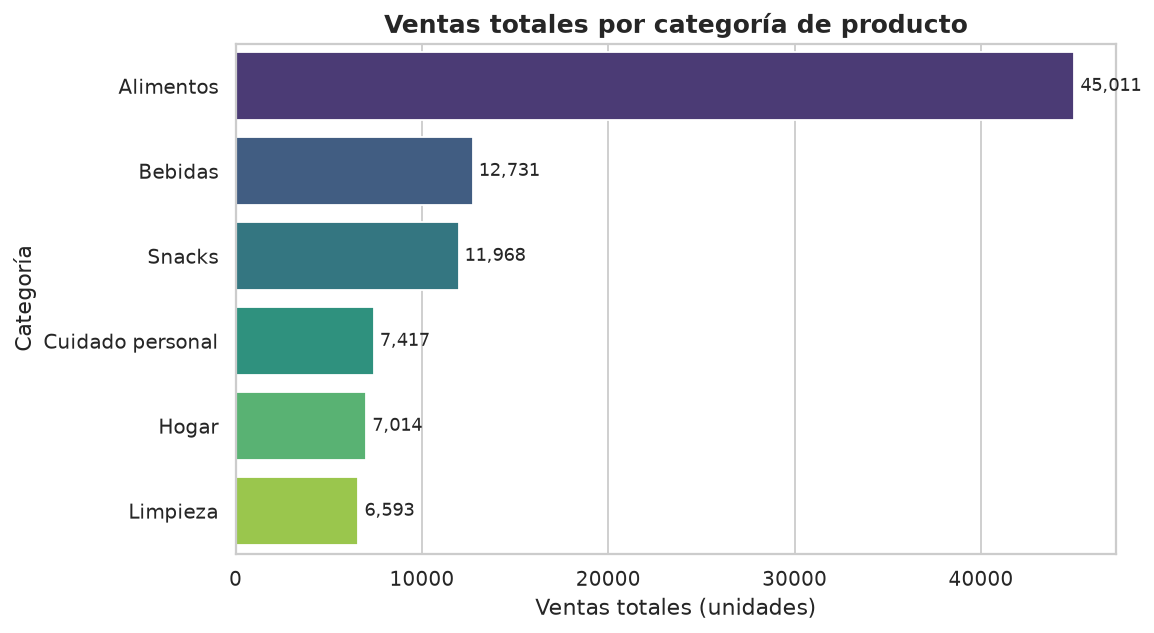

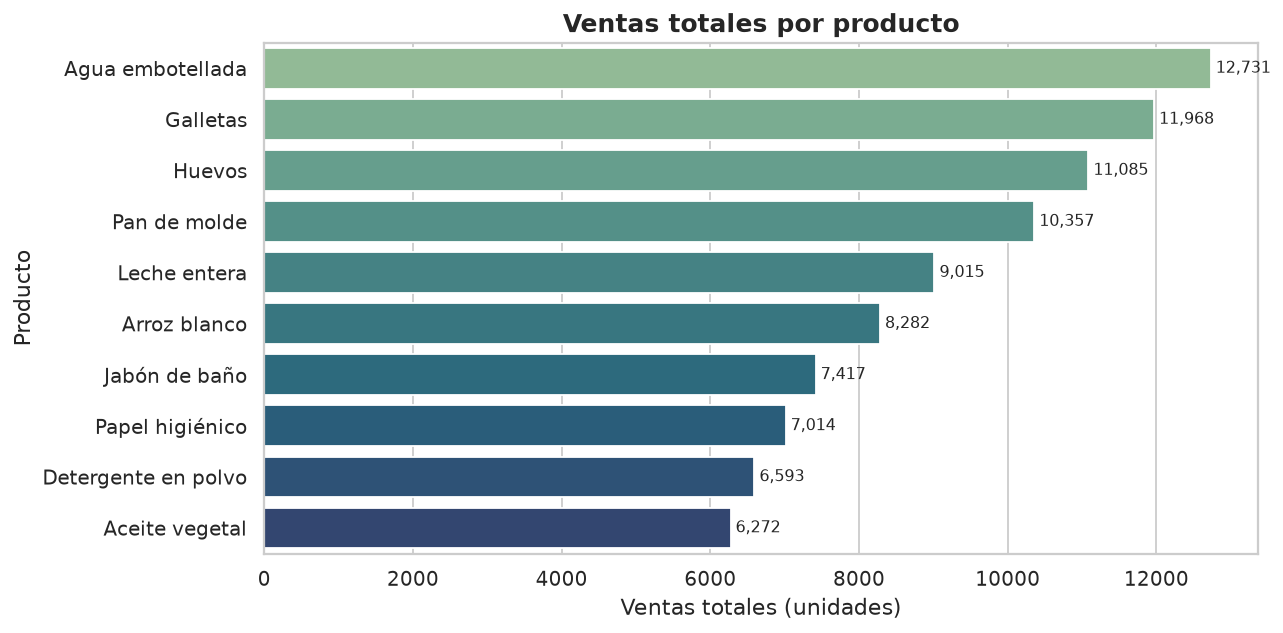

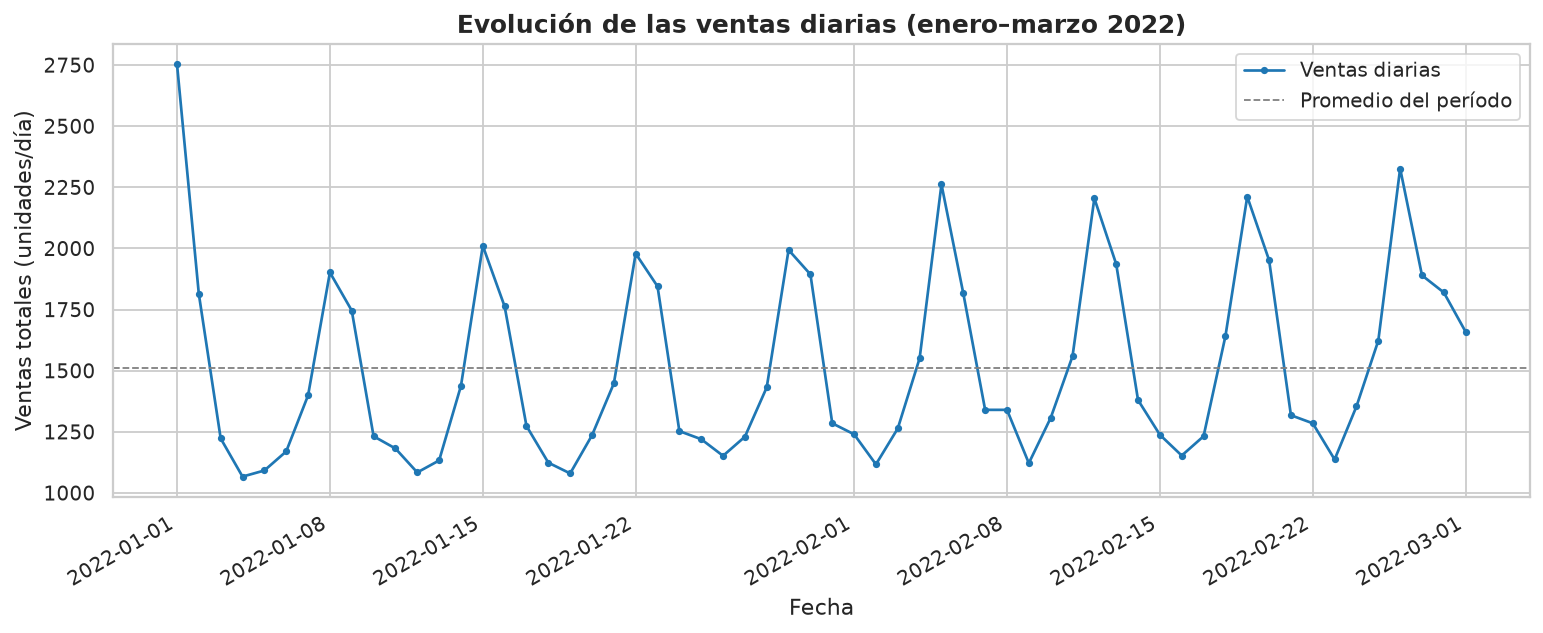

In [11]:
from IPython.display import Image, display
import matplotlib.pyplot as plt

# Generamos todas las figuras con df_feat (ya con variables temporales)
generar_todas_las_figuras(df_feat, '../figuras')

display(Image(filename='../figuras/01_ventas_por_categoria.png'))
display(Image(filename='../figuras/02_ventas_por_producto.png'))
display(Image(filename='../figuras/03_evolucion_diaria.png'))


### 6.2 Comportamiento semana a semana (2 meses)

El requisito pide organizar las imágenes **semana a semana durante un período de dos meses**.


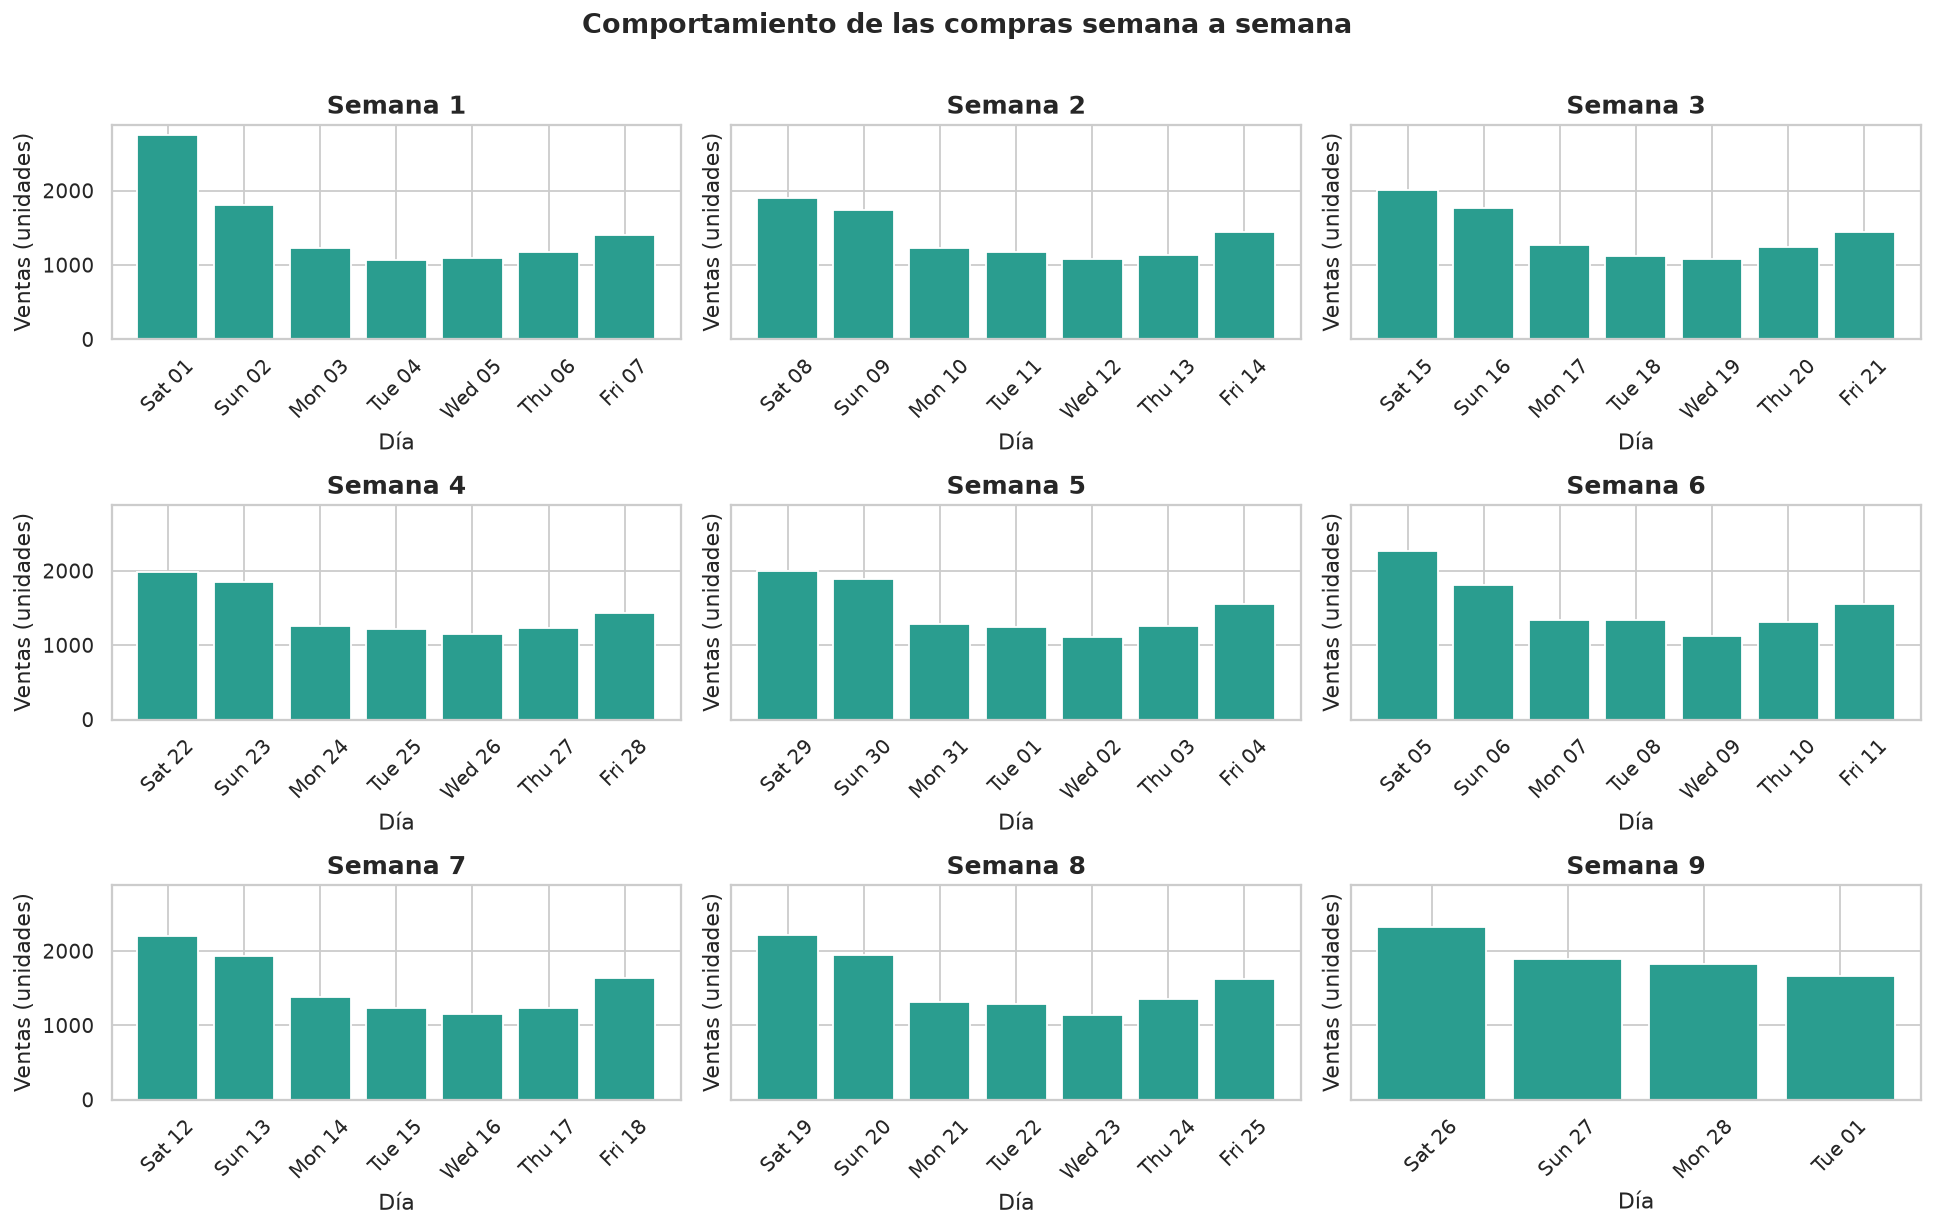

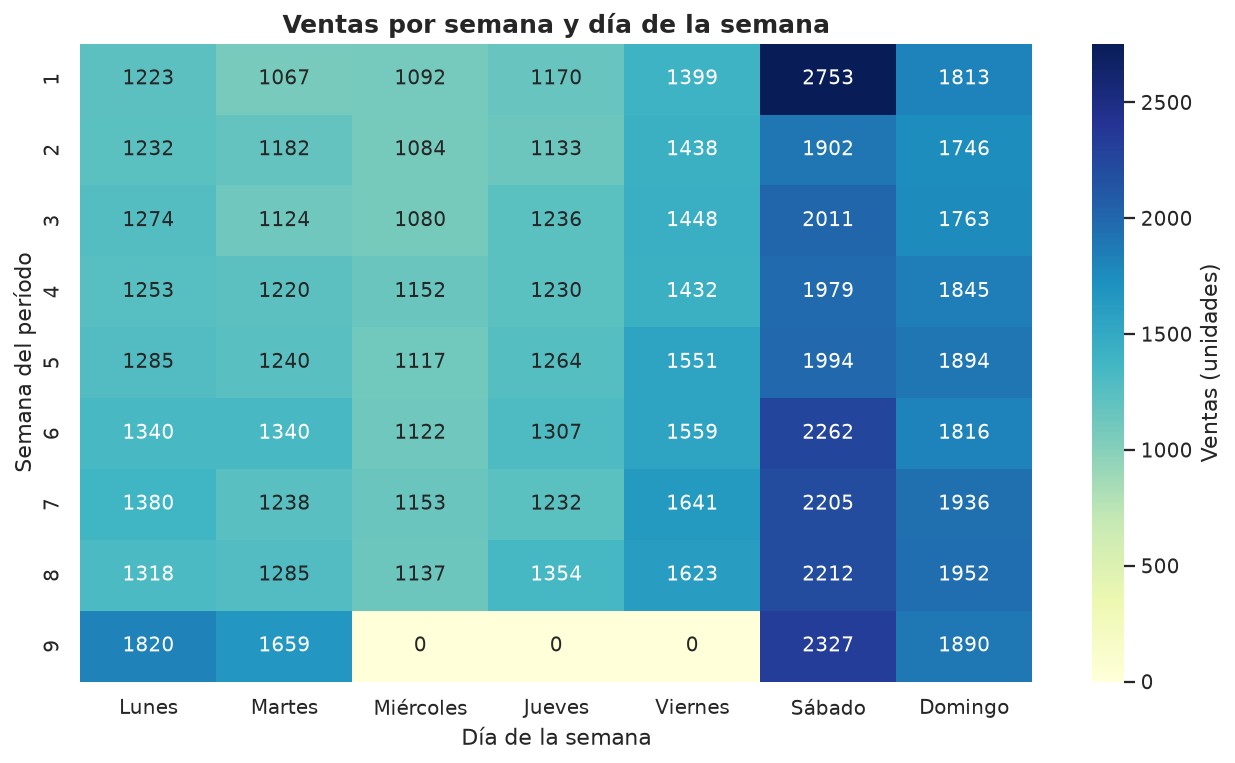

In [12]:
display(Image(filename='../figuras/04_semana_a_semana.png'))
display(Image(filename='../figuras/05_heatmap_semana_dia.png'))


### 6.3 Muestreo de categorías

Se realiza un muestreo de categorías para facilitar el análisis y la visualización.


Categorías muestreadas: ['Alimentos', 'Hogar', 'Snacks']


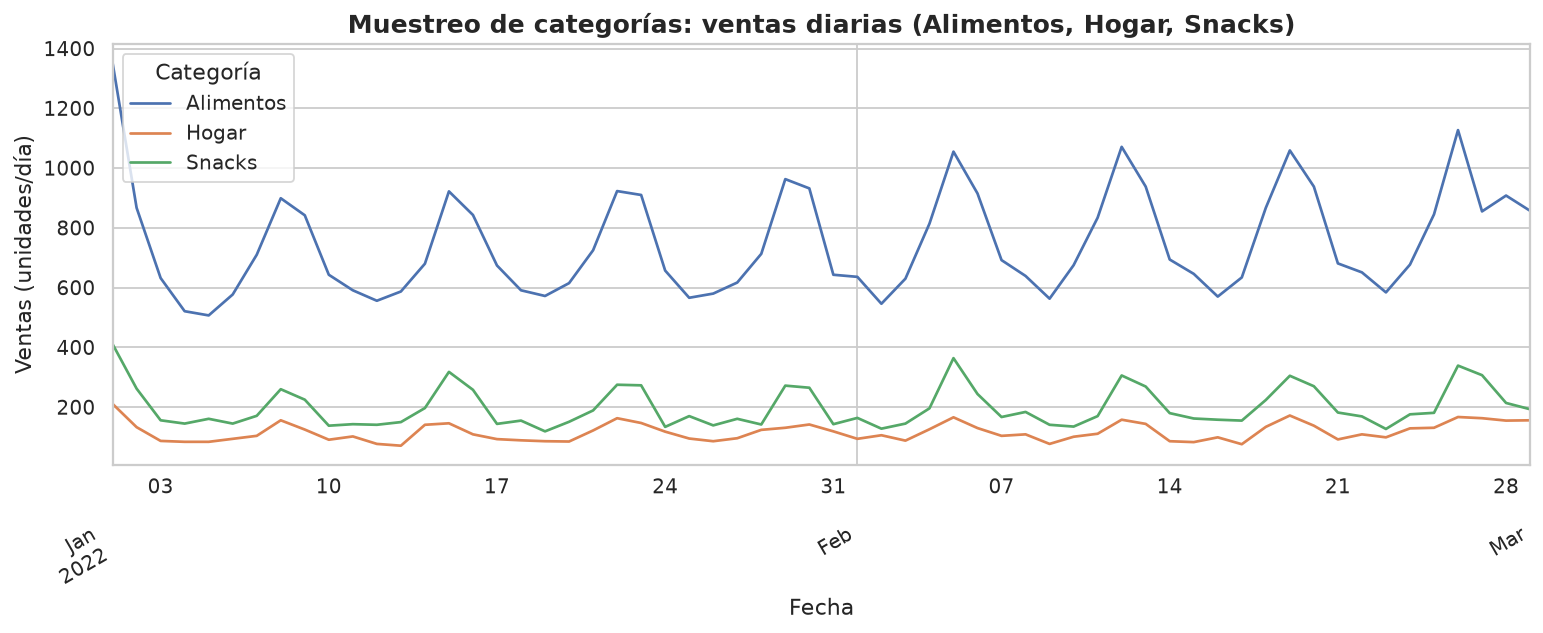

In [13]:
cats_muestra = muestrear_categorias(df_feat, n=3)
print('Categorías muestreadas:', cats_muestra)
display(Image(filename='../figuras/06_categorias_en_tiempo.png'))


## 7. Análisis de las variables creadas (Fin de semana y Feriados)

Ahora se analiza el **efecto** de las variables creadas sobre las ventas.

### 7.1 Fin de semana vs entre semana


In [14]:
comparar_fin_de_semana(df_feat)


,tipo_dia,venta_promedio_diaria,dias,ventas_totales
0,Entre semana,1296.0,42,54434
1,Fin de semana,2016.7,18,36300


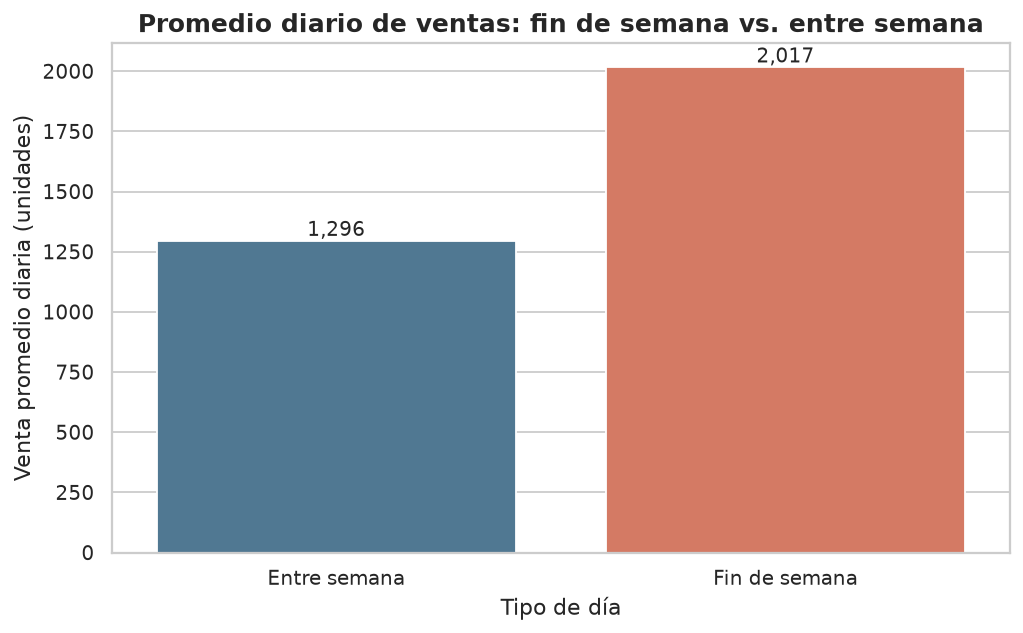

In [15]:
display(Image(filename='../figuras/07_fin_de_semana.png'))


### 7.2 Influencia de los feriados


In [16]:
comparar_feriados(df_feat, pais='EC')


,feriado,venta_promedio_diaria,dias,ventas_totales
0,No feriado,1482.5,57,84502
1,Feriado,2077.3,3,6232


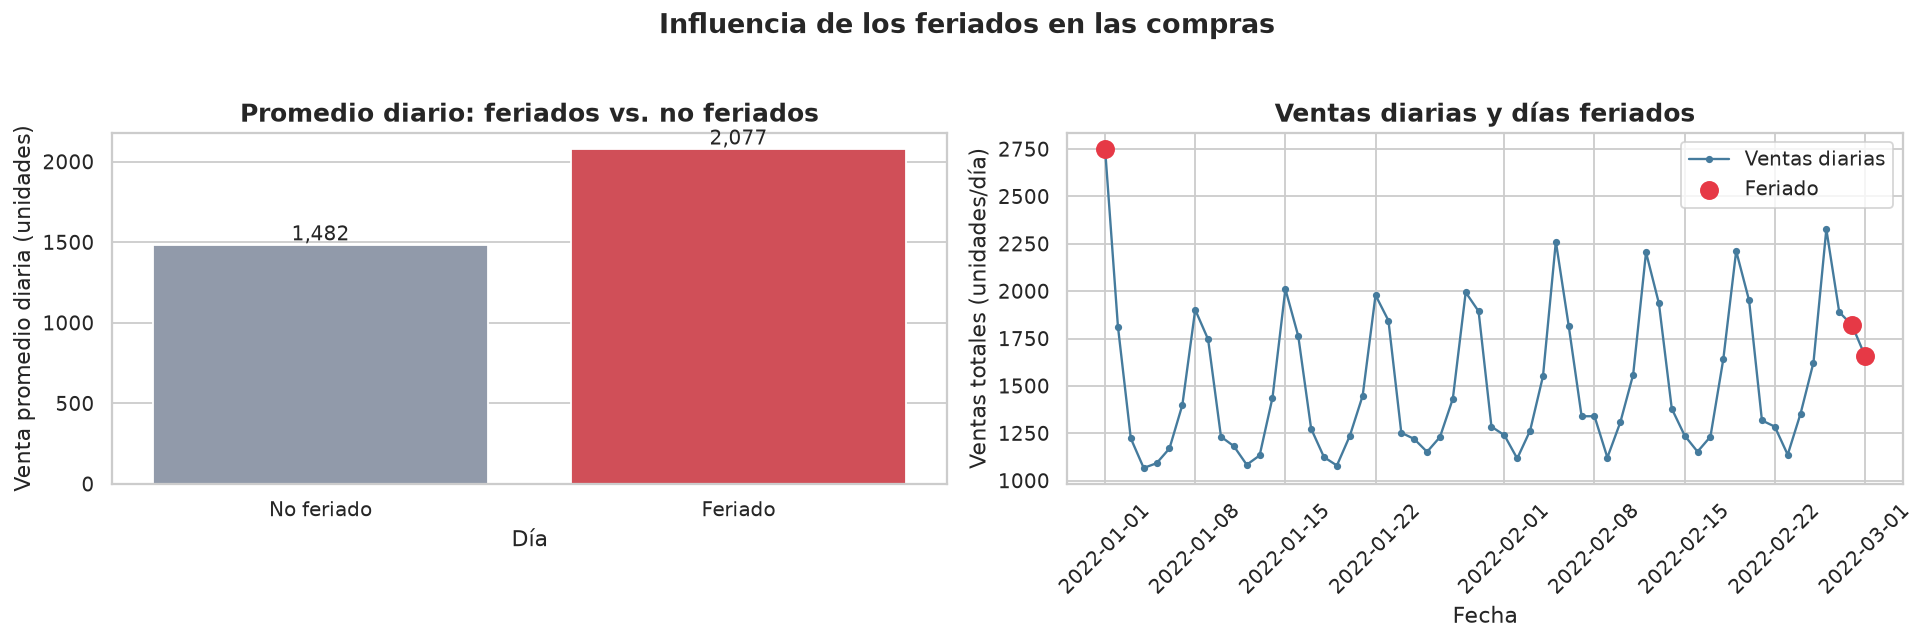

In [17]:
display(Image(filename='../figuras/08_feriados.png'))


### 7.3 Distribuciones y relación stock-ventas


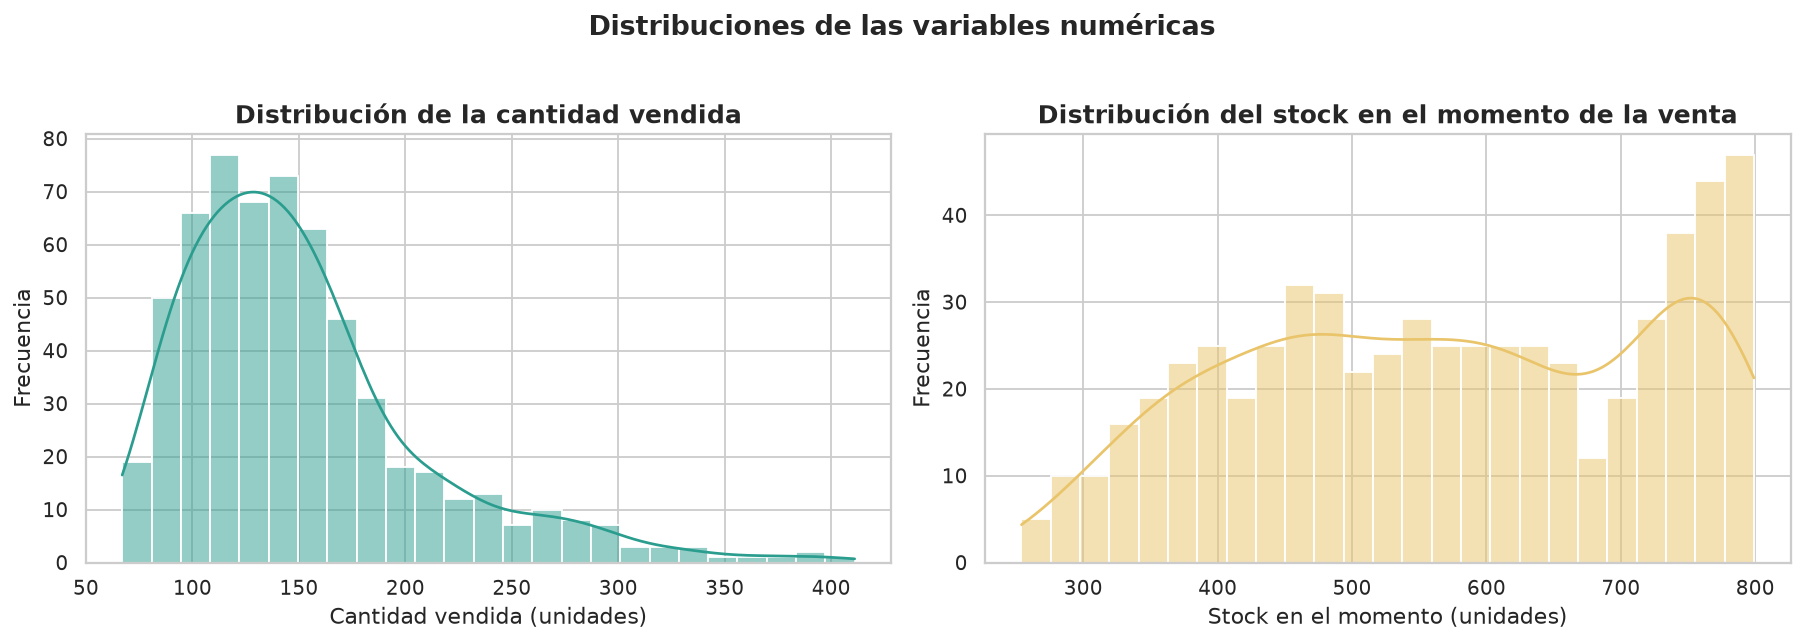

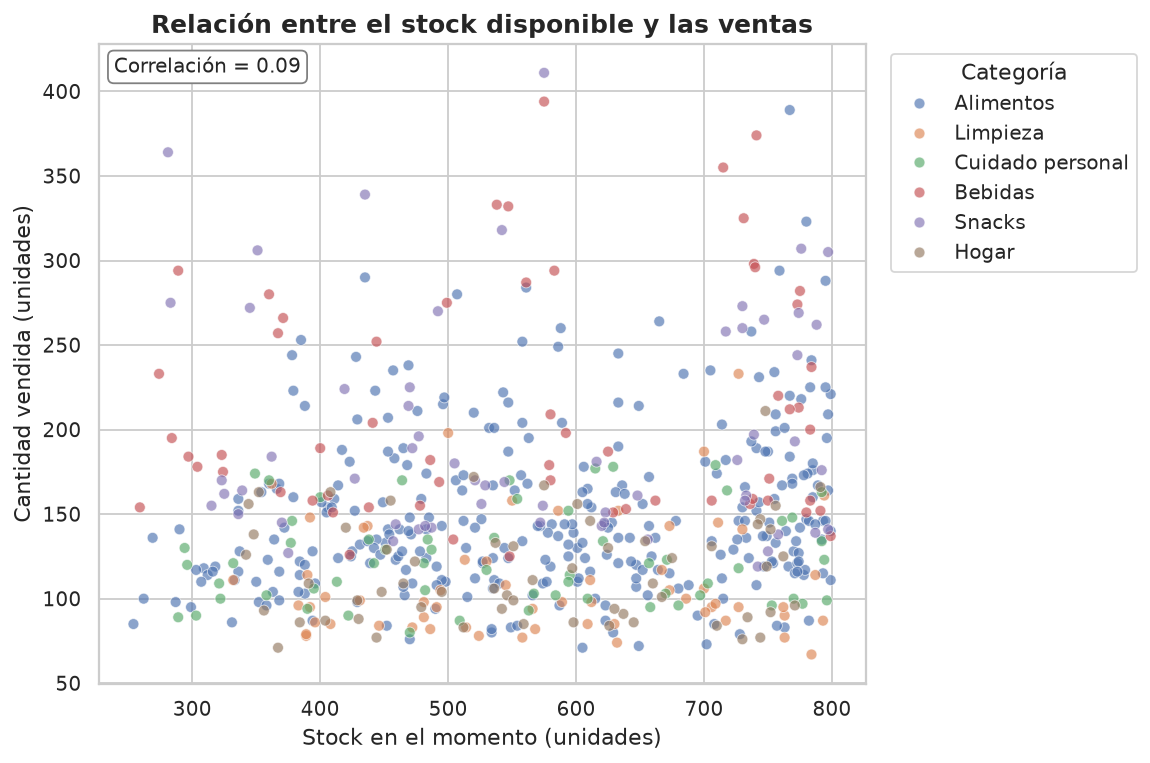

In [18]:
display(Image(filename='../figuras/09_distribuciones.png'))
display(Image(filename='../figuras/10_stock_vs_ventas.png'))


## 8. Figura: 3 categorías más representativas por semana

Una **sola figura entendible** que muestra la **fluctuación en la semana** para **dos o tres categorías**.

Se toman las **3 categorías más representativas**: **Alimentos, Bebidas y Snacks**. La figura muestra las **ventas totales semanales por categoría**, lo que permite observar tanto su **tendencia/histórico** como su **fluctuación por semana** a lo largo del período.


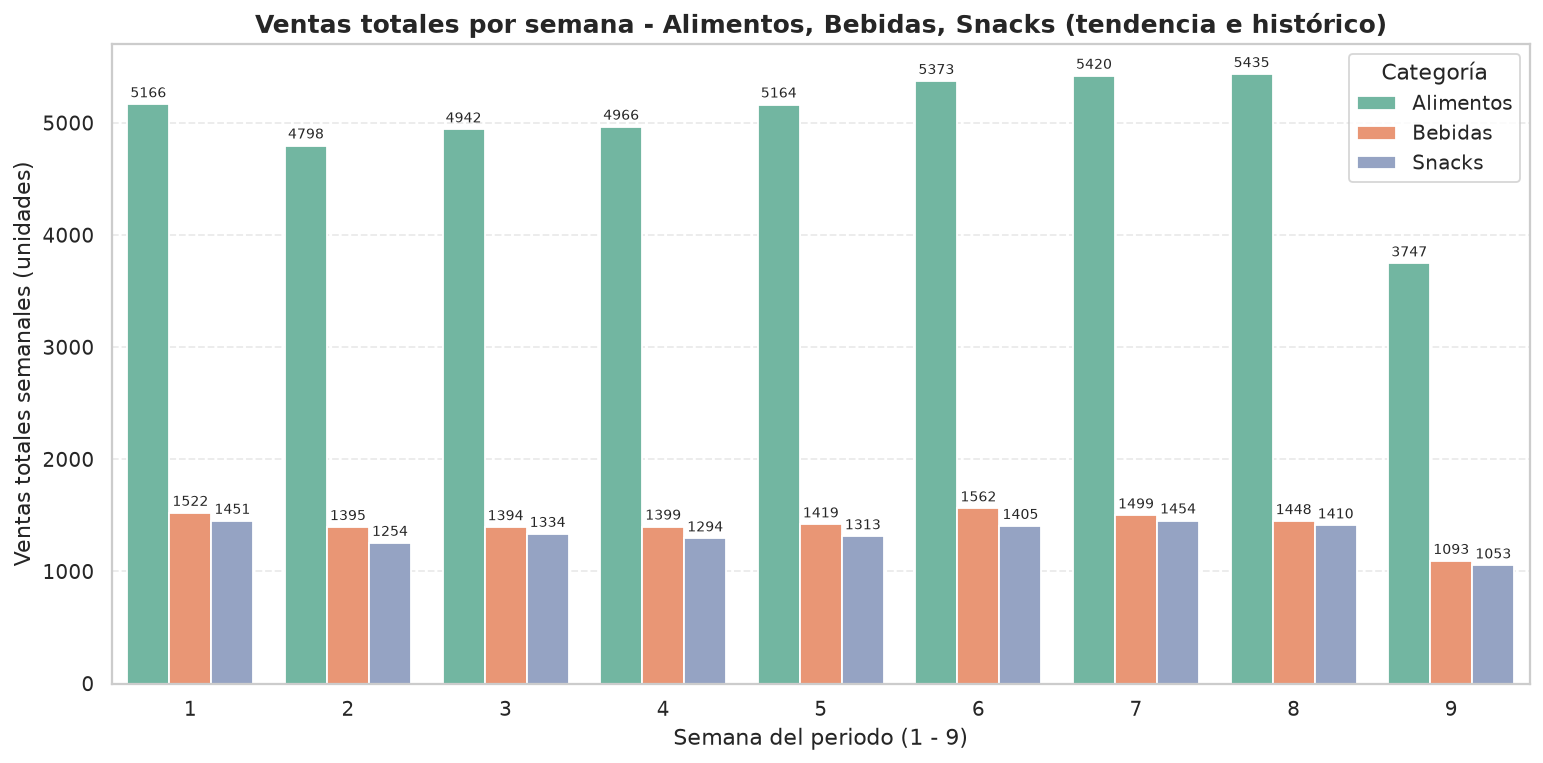

In [19]:
display(Image(filename='../figuras/11_tres_categorias_por_semana.png'))


In [20]:
tmp = df_feat[df_feat['categoria'].isin(['Alimentos','Bebidas','Snacks'])]
semanal = tmp.groupby(['semana_del_periodo','categoria'])['cantidad_vendida'].sum().unstack(fill_value=0)
semanal['Total'] = semanal.sum(axis=1)
semanal


categoria,Alimentos,Bebidas,Snacks,Total
semana_del_periodo,,,,
1,5166,1522,1451,8139
2,4798,1395,1254,7447
3,4942,1394,1334,7670
4,4966,1399,1294,7659
5,5164,1419,1313,7896
6,5373,1562,1405,8340
7,5420,1499,1454,8373
8,5435,1448,1410,8293
9,3747,1093,1053,5893


## 9. Criterios del análisis

- **Patrones reconocibles:** Se observa mayor venta los sábados/domingo y un incremento claro en días feriados. Las figuras muestran un ciclo semanal repetitivo.
- **Comprensión del negocio:** En una tienda de barrio la demanda se concentra en fin de semana y feriados. Las variables `es_fin_de_semana` y `es_feriado` responden a eso.
- **Muestreo:** Se realizó muestreo de categorías y se analizan explícitamente las 3 más representativas por semana.
- **Organización temporal:** Se trabajó con 9 semanas (60 días). Figuras semana a semana y heatmap semana x día.
- **Calidad de las figuras:** Cada figura tiene **título** y **nombres en ejes X e Y**.
- **Variables justificadas:** Las creadas permiten modelar estacionalidad semanal, efecto calendario y memoria temporal (rezagos).


## 10. Preparación para el modelo (secuencias temporales)

Para un modelo de series temporales (RNN/LSTM) por producto o categoría, se construyen **secuencias** con ventana temporal.

Ejemplo: predecir `cantidad_vendida` del día t usando los últimos 7 días (features temporales + indicadores).


In [21]:
df_seq = df_feat.sort_values(['product_id','fecha_venta']).copy()
ventana = 7
secuencias = []

for pid, g in df_seq.groupby('product_id'):
    vals = g[['cantidad_vendida','es_fin_de_semana','es_feriado','dia_semana']].values
    for i in range(ventana, len(vals)):
        Xw = vals[i-ventana:i]
        yw = vals[i, 0]
        secuencias.append((pid, i, Xw.shape, yw))

print('Muestras por producto (ventana=7):', len(secuencias))
print('Forma ejemplo X:', secuencias[0][2], '| y:', secuencias[0][3])


Muestras por producto (ventana=7): 530
Forma ejemplo X: (7, 4) | y: 171


## 11. Conclusiones

- **Dataset:** Se identificó el origen público en Kaggle. El dataset analizado fue **construido** a partir de él, con modificaciones documentadas (traducción, selección de 10 productos, recorte a 60 días, incorporación de estacionalidad y feriados de Ecuador).
- **Orden correcto:** Las **variables temporales e indicadores** se generaron **antes** del análisis exploratorio, asegurando que todas las visualizaciones las utilicen correctamente.
- **Patrón de compras:** Existe un patrón claro. El **sábado** es el día con mayor venta frente al **miércoles**. El fin de semana supera al entre semana en **+55.6%**.
- **Feriados:** Los feriados influyen positivamente (**+40.1%**). Aunque solo hay 3 feriados en la ventana, el efecto es reconocible.
- **Categorías:** Alimentos lidera en total (49.6%), pero Bebidas/Snacks son muy rotativos. El análisis **por semana** de las 3 categorías más representativas muestra su fluctuación clara entre semanas.
- **Variables:** Se crearon variables temporales, `es_fin_de_semana`, `es_feriado`, `tipo_dia` (4 niveles sin pérdida), rezagos y promedio móvil, justificadas desde el negocio.
- **Listo para modelado:** El dataset queda preparado para construir secuencias temporales por producto/categoría en la siguiente fase.


## 12. Anexo: Reproducibilidad

Desde la raíz del proyecto:

```bash
pyenv local 3.12.7
python -m venv .venv
.venv/bin/python -m pip install -r requirements.txt

# Regenerar dataset sintético
.venv/bin/python src/fase1/generar_dataset.py

# Generar figuras y análisis
.venv/bin/python src/fase1/analisis_exploratorio.py

# Feature engineering
.venv/bin/python src/fase1/feature_engineering.py

# Reporte y presentación
.venv/bin/python src/fase1/generar_reporte.py
```

**Archivos generados:**
- `datos/inventory.csv`, `datos/sales_history.csv`, `datos/ventas_features.csv`
- `figuras/01_*.png` ... `figuras/11_tres_categorias_por_semana.png`
- `reporte/reporte_tarea01.pdf`, `presentacion/presentacion_tarea01.pdf`
- `notebooks/tarea01_ingenieria_caracteristicas.ipynb` (esta libreta)
